# 01 · The ITCH 5.0 feed: framing, decoding, timeline

**Question:** what is actually in a Nasdaq TotalView-ITCH file, and can the parser be trusted before we build anything on it?

The file is the first 300 MB (04:00 to 09:30:36) of Nasdaq's real ITCH 5.0 feed for **30 December 2019**. It is a stream of binary messages: a 2-byte big-endian length, then a body that starts with a 1-byte type and an 11-byte header (type, stock locate, tracking number, 48-bit nanosecond timestamp). There are no delimiters, so message *n+1* can only be found by reading the length of message *n*.

The cut at 300 MB matters for everything below: this is **pre-market, the opening cross, and 36 seconds of regular trading**, not a full day.

In [1]:
import struct, time, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itch_forensics.framing import index_messages, length_mismatches
from itch_forensics.decode import decode, decode_all
from itch_forensics.checks import header_frame, timestamp_regressions
from itch_forensics.spec import EXPECTED_LENGTH, NAME

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
buf = pathlib.Path("../data/itch.bin").read_bytes()
print(f"{len(buf):,} bytes")

300,000,000 bytes


## Framing

One sequential pass over the length prefixes. Then every message length is compared with the length the ITCH 5.0 specification gives for that type.

In [2]:
t = time.time(); idx = index_messages(buf); dt = time.time() - t
print(f"{len(idx):,} messages indexed in {dt:.1f} s;  {idx.trailing} trailing bytes (the cut landed inside the last message)")
mix = (pd.Series([chr(t) for t in idx.types]).value_counts().rename("messages").to_frame()
         .assign(name=lambda d: [NAME.get(i, "?") for i in d.index],
                 spec_length=lambda d: [EXPECTED_LENGTH.get(i) for i in d.index]))
mix["share_%"] = (100 * mix.messages / mix.messages.sum()).round(2)
mix

8,733,895 messages indexed in 3.2 s;  34 trailing bytes (the cut landed inside the last message)


,messages,name,spec_length,share_%
A,3179119,add_order,36,36.40
D,2362895,order_delete,19,27.05
I,1073085,noii,50,12.29
F,752977,add_order_mpid,40,8.62
U,532923,order_replace,35,6.10
X,519657,order_cancel,23,5.95
L,215087,participant_position,26,2.46
E,48147,order_executed,31,0.55
P,13036,trade,44,0.15
R,8906,stock_directory,39,0.10


In [3]:
bad = length_mismatches(idx)
print("messages whose length differs from the spec:", bad or "none")
unknown = [chr(t) for t in np.unique(idx.types) if chr(t) not in EXPECTED_LENGTH]
print("message types not in the layout table:", unknown or "none")

messages whose length differs from the spec: none
message types not in the layout table: none


Every observed length matches the spec, and every type present is one the parser knows.

## One message, decoded by hand

The first add-order message in the file, as raw bytes, then field by field with `struct.unpack`:

In [4]:
first_a = int(np.flatnonzero(idx.types == ord("A"))[0])
o, ln = int(idx.offsets[first_a]), int(idx.lengths[first_a])
body = buf[o:o + ln]
print(body.hex(" "))
_, locate, tracking, ts_hi, ts_lo, ref, side, shares, stock, price = struct.unpack(">cHHHIQcI8sI", body)
by_hand = dict(locate=locate, ts_ns=(ts_hi << 32) | ts_lo, ref=ref, side=side.decode(), shares=shares,
               stock=stock.decode().rstrip(), price=price)
print(by_hand)

41 01 f0 00 00 0d 18 c2 ed 8d a2 00 00 00 00 00 00 22 b1 42 00 00 07 d0 41 52 47 58 20 20 20 20 00 18 80 a8
{'locate': 496, 'ts_ns': 14400000724386, 'ref': 8881, 'side': 'B', 'shares': 2000, 'stock': 'ARGX', 'price': 1605800}


In [5]:
a = decode(buf, idx, "A")
vec = a.iloc[0]
assert (vec.locate, vec.ts_ns, vec.ref, vec.side, vec.shares, vec.stock, vec.price) == tuple(by_hand.values())
print("vectorised decoder agrees on this message")
print(f"price {vec.price} = ${vec.price / 10_000:.4f}  (prices are integers with 4 implied decimals)")

vectorised decoder agrees on this message
price 1605800 = $160.5800  (prices are integers with 4 implied decimals)


Now the same check at scale: decode every add, execute and replace message a second time with plain `struct.unpack` in a Python loop and compare with the numpy decoder, field by field.

In [6]:
def reference(msg_type, fmt, length):
    rows = []
    for off in idx.offsets[idx.types == ord(msg_type)]:
        rows.append(struct.unpack(fmt, buf[off:off + length]))
    return rows

t = time.time()
ref_a = reference("A", ">cHHHIQcI8sI", 36)
ref_e = reference("E", ">cHHHIQIQ", 31)
ref_u = reference("U", ">cHHHIQQII", 35)
print(f"reference decode of {len(ref_a)+len(ref_e)+len(ref_u):,} messages in {time.time()-t:.0f} s")

e, u = decode(buf, idx, "E"), decode(buf, idx, "U")
ok_a = (a.ref.to_numpy() == np.array([r[5] for r in ref_a], dtype=np.uint64)).all() and \
       (a.price.to_numpy() == np.array([r[9] for r in ref_a])).all() and \
       (a.shares.to_numpy() == np.array([r[7] for r in ref_a])).all() and \
       (a.ts_ns.to_numpy() == np.array([(r[3] << 32) | r[4] for r in ref_a])).all() and \
       (a.stock.astype(str).to_numpy() == np.array([r[8].decode().rstrip() for r in ref_a])).all()
ok_e = (e.match.to_numpy() == np.array([r[7] for r in ref_e], dtype=np.uint64)).all() and \
       (e.shares.to_numpy() == np.array([r[6] for r in ref_e])).all()
ok_u = (u.new_ref.to_numpy() == np.array([r[6] for r in ref_u], dtype=np.uint64)).all() and \
       (u.price.to_numpy() == np.array([r[8] for r in ref_u])).all()
print("add / execute / replace fields identical to the reference parse:", ok_a, ok_e, ok_u)
assert ok_a and ok_e and ok_u

reference decode of 3,760,189 messages in 3 s


add / execute / replace fields identical to the reference parse: True True True


## Timeline of the session

`S` messages mark the phases of the day. Timestamps are nanoseconds since midnight.

In [7]:
s = decode(buf, idx, "S")
meaning = {"O": "start of messages", "S": "start of system hours", "Q": "start of market hours"}
s["clock"] = pd.to_timedelta(s.ts_ns, unit="ns").astype(str).str[-18:-3]
s["meaning"] = s.event_code.astype(str).map(meaning)
s[["seq", "event_code", "meaning", "clock"]]

,seq,event_code,meaning,clock
0,0,O,start of messages,03:04:32.057543
1,241732,S,start of system hours,04:00:00.000198
2,6696721,Q,start of market hours,09:30:00.000075


In [8]:
h = header_frame(buf, idx)
print(timestamp_regressions(h))
last = pd.to_timedelta(h.ts_ns.max(), unit="ns")
print("last message in the sample:", str(last)[-18:-3])

{'messages': 8733895, 'regressions': 0, 'largest_step_back_ns': 0, 'same_timestamp_pairs': 857720}
last message in the sample: 09:30:36.339466


Timestamps never go backwards across 8.7 million messages. About 857,000 consecutive pairs share an identical timestamp, which is normal: the clock has nanosecond resolution but events can be stamped in the same tick.

## Where the volume is

Messages per hour of the day, and the single busiest second:

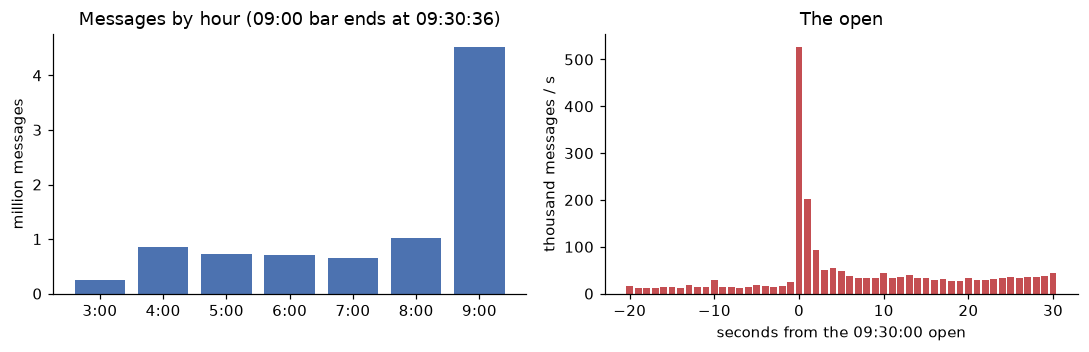

busiest second: 0 days 09:30:00 with 527,644 messages (3068x the median second of 172)


In [9]:
sec = (h.ts_ns // 1_000_000_000)
per_sec = sec.value_counts().sort_index()
hourly = per_sec.groupby(per_sec.index // 3600).sum()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
ax[0].bar(hourly.index.astype(str) + ":00", hourly.values / 1e6, color="#4C72B0")
ax[0].set_ylabel("million messages"); ax[0].set_title("Messages by hour (09:00 bar ends at 09:30:36)")
win = per_sec[(per_sec.index >= 34200 - 20) & (per_sec.index <= 34200 + 30)]
ax[1].bar(win.index - 34200, win.values / 1e3, color="#C44E52")
ax[1].set_xlabel("seconds from the 09:30:00 open"); ax[1].set_ylabel("thousand messages / s")
ax[1].set_title("The open"); plt.tight_layout(); plt.show()
top = per_sec.nlargest(1)
print(f"busiest second: {pd.to_timedelta(top.index[0], unit='s')} with {top.iloc[0]:,} messages "
      f"({top.iloc[0] / per_sec.median():.0f}x the median second of {per_sec.median():.0f})")

## What this means for what follows

1. The framing is exactly as specified and the decoder agrees with an independent parse, so later findings are about the *feed*, not about parser bugs.
2. The sample starts at the beginning of the day, so the order book starts empty. That is what makes the order-book audit in notebook 02 meaningful: any message that refers to an unknown order is a real anomaly, not a window artifact.
3. The sample ends 36 seconds after the open. Anything that needs the rest of the day (end-of-day volumes, the closing cross) is out of scope.

Next: [02 · Rebuilding the order book](02_order_book.ipynb)